In [24]:
from astropy.io import fits
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import Functions
from scipy.optimize import curve_fit

#Values for photometric calibration (obtained from photometry table in Brightspace)
PHOTOFLAM = 1.115396e-16 #Inverse Sensitivity
PHOTZPT = -21.1 #Zero point
PHOTPLAM = 3359.474 #Pivot wavelength
PHOTBW = 204.4908 #RMS bandwidth of the filter
ZP_CORR = -0.03288031 #Delta magnitude correction for contamination

In [ ]:
%matplotlib widget

In [25]:
here = Path(".")

##Paths to each folder
ubai2505m = here/'hst-data/Calibration/ubai2505m'
ubai2507m = here/'hst-data/Calibration/ubai2507m'
ubai2508m = here/'hst-data/Calibration/ubai2508m'

In [26]:
#Obtain all the files needed for calibration
#INPUTS: name of the file, folder from where you want to obtain the file
raw_file = Functions.obtain_files("raw", ubai2507m)
blev_file = Functions.obtain_files("blev", ubai2507m)
bias_file = Functions.obtain_files("bias", ubai2507m)
dark_file = Functions.obtain_files("dark", ubai2507m)
flat_file = Functions.obtain_files("flat", ubai2507m)
mask_file = Functions.obtain_files("mask", ubai2507m)

#Extract the data needed for calibration from the file 
#INPUT: name of the file, file obtained from previous function
raw_data = Functions.obtain_data("raw7", raw_file)
blev_data = Functions.obtain_data("blev7", blev_file)
bias_data = Functions.obtain_data("bias", bias_file)
dark_data = Functions.obtain_data("dark", dark_file)
flat_data = Functions.obtain_data("flat", flat_file)
mask_data = Functions.obtain_data("mask", mask_file)

#Extract exposure time
time = Functions.exp_time(raw_file)

#Apply the mask data to the raw data
mask = Functions.masking(mask_data, raw_data)

#Apply the blev data
blev_corr = Functions.apply_blev(blev_data,mask, "blev7")

#Remove the bias data
bias_correct = Functions.apply_bias(bias_data, blev_corr)

#Remove the dark data
dark_correct = Functions.apply_dark(dark_data, bias_correct, time)

#Remove the flat data
flat_correct = Functions.apply_flat(flat_data, dark_correct)

#Remove sky estimation
sky_correct = Functions.calculate_mean_and_stndev(flat_correct)


Text(0.5, 1.0, 'Calibrated ubai2507m')

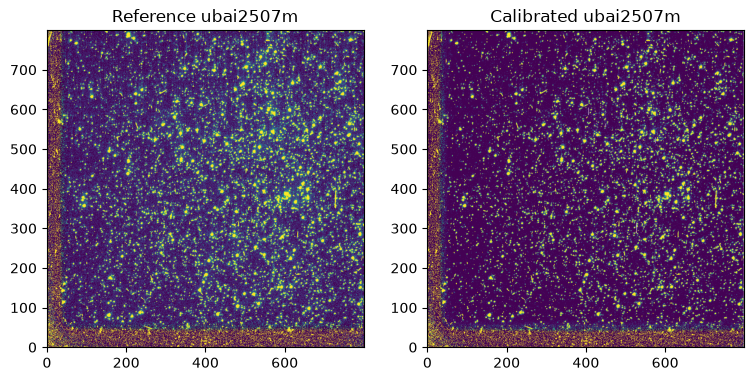

In [27]:
ubai2507m_aligned = here/'hst-data/F336W/ubai2507m_c0m_aligned.fits'#science-ready files
#obtain image from science-ready files
with fits.open(ubai2507m_aligned) as hdul:
            aligned2507 = hdul[1].data

plt.close('all')
#Plot to compare science-ready files to the performed image calibration
pc_data = aligned2507.copy()
pc_datacal = sky_correct[0].copy()

fig, (ax, ax1) = plt.subplots(1,2,figsize=(9, 9))

ax.imshow(pc_data, origin='lower', vmin=0, vmax=5)
ax.set_title("Reference ubai2507m")

ax1.imshow(pc_datacal, origin='lower', vmin=0, vmax=5)
ax1.set_title("Calibrated ubai2507m")

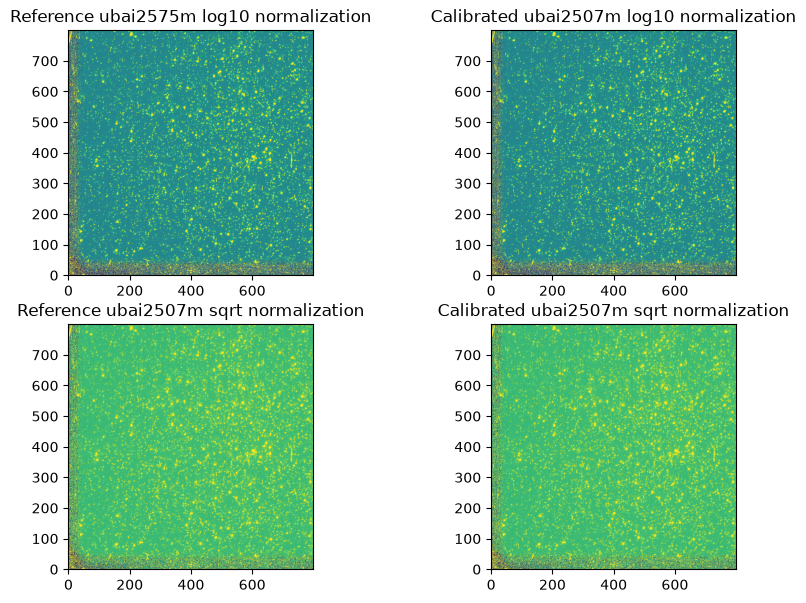

In [28]:
#transform/stretch the data to make faint pixels visible without making the visible pixels too bright
counts = np.nan_to_num(pc_datacal, nan=0)

pc_log = Functions.transform_by('log', pc_data, pmin=1, pmax=95)#log10 normalization
pc_logcal = Functions.transform_by('log', counts, pmin=1, pmax=95)#log10 normalization

fluxsqrt = Functions.transform_by('sqrt', pc_data, pmin=1, pmax=95)#sqrt normalization
fluxsqrtcal = Functions.transform_by('sqrt', counts, pmin=1, pmax=95)#sqrt normalization

#plot
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2,2, figsize=(10, 7))
ax1.imshow(pc_log, origin='lower')
ax1.set_title("Reference ubai2507m log10 normalization")
ax2.imshow(pc_logcal, origin='lower')
ax2.set_title("Calibrated ubai2507m log10 normalization")
ax3.imshow(fluxsqrt, origin='lower')
ax3.set_title("Reference ubai2507m sqrt normalization")
ax4.imshow(fluxsqrtcal, origin='lower')
ax4.set_title("Calibrated ubai2507m sqrt normalization")
plt.show()

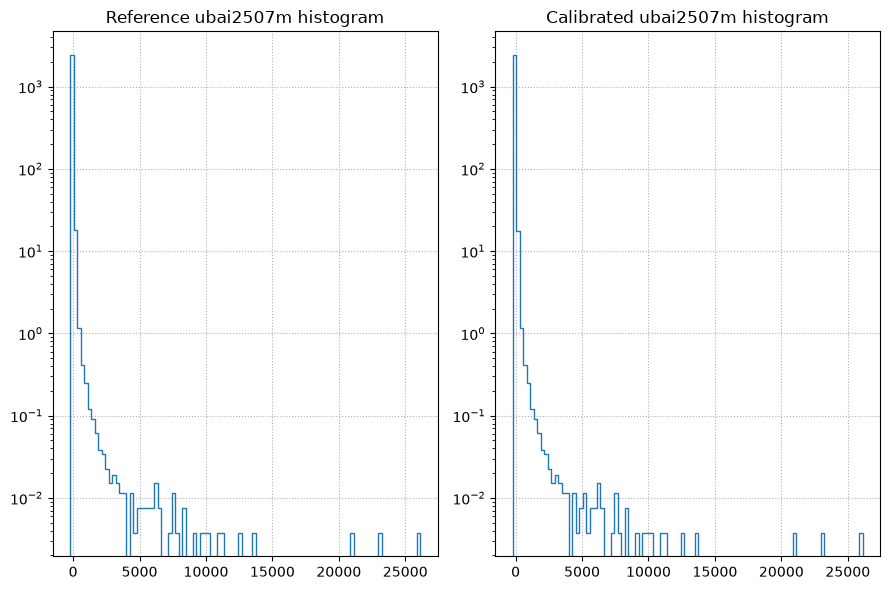

In [16]:
#Make histrogram to compare the counts from both the science-ready files to the calibrated files
counts = np.nan_to_num(pc_datacal, nan=0) #remove nan from masking - make nan be 0

fig2, (ax,ax1) = plt.subplots(1,2,figsize=(9, 6))

Functions.histogram(ax, pc_data)
Functions.histogram(ax1, counts)

ax.set_yscale('log')
ax1.set_yscale('log')

ax.set_title("Reference ubai2507m histogram")
ax1.set_title("Calibrated ubai2507m histogram")

ax.grid(ls=':')
ax1.grid(ls=':')

plt.tight_layout()

In [17]:
#Convert to flux
aligned = Functions.flux(time, PHOTOFLAM,aligned2507)
maskp = ~np.isnan(sky_correct[0])
Cal = Functions.flux(time, PHOTOFLAM, sky_correct[0][maskp])

ma= aligned.mean()
mc =Cal.mean()

photo = [ma, mc]

mag = Functions.magnitude(photo, PHOTOFLAM,ZP_CORR)

print(f"The mean flux of the reference data is {ma}, and of the calibrated data is {mc}")
print(f"\nFlux {ma} magnitude is {mag[0]}")
print(f"Flux {mc} magnitude is {mag[1]}")

The mean flux of the reference data is 5.220530827042014e-19, and of the calibrated data is 3.680797034774325e-19

Flux 5.220530827042014e-19 magnitude is 45.672833028502815
Flux 3.680797034774325e-19 magnitude is 46.05226501401968


In [18]:
from scipy.ndimage import gaussian_filter, convolve
#Calculate the possible sources from the science-ready data and calibrated files
filtered_image = gaussian_filter(Cal , sigma=1, mode='reflect')#find source

filtered_image.min(), filtered_image.max()

coords1 = Functions.get_local_max(aligned2507)
coords2 = Functions.get_local_max(sky_correct[0])

The maximum_filter found 4986 possible sources
The maximum_filter found 4971 possible sources


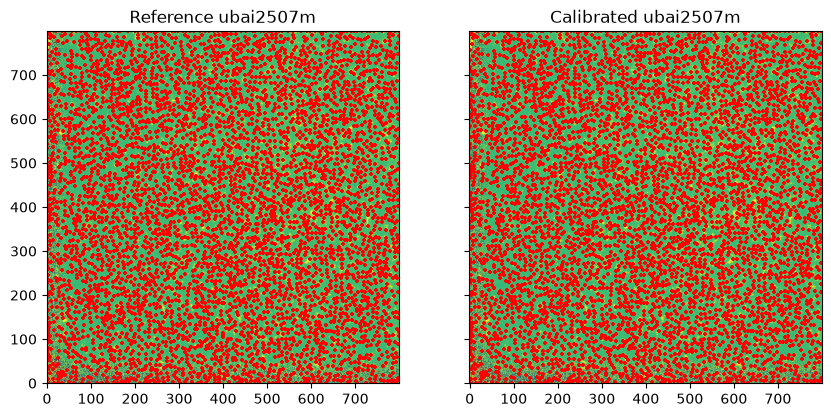

In [19]:
#Plot the possible sources found
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 5), sharex=True, sharey=True)

ax1.imshow(fluxsqrt, origin='lower')
ax2.imshow(fluxsqrtcal, origin='lower')
ax1.set_title("Reference ubai2507m")
ax2.set_title("Calibrated ubai2507m")
ax1.scatter(coords1[:, 1], coords1[:, 0], s=10, marker='+', c='r', label='basic max filter')
ax2.scatter(coords2[:, 1], coords2[:, 0], s=10, marker='+', c='r', label='gaussian filtered max filter')
plt.show()

In [20]:
#Coordinates for three astronomical sources
test_coords = [[700, 350], [470, 369], [150, 550] ]

aligngauss = []
for val in test_coords:
    #initial parameter for the 2d gaussian
    p0al = [
        aligned.max(), # amplitude
        val[1], # x center
        val[0], # y center
        0.5, # sigx
        0.5 # sigy
    ]
    poptal, pcoval = Functions.fit_gauss_2d(aligned, init_par=p0al)
    aligngauss.append(poptal) #store the gaussian parameters for each source 
   
calibrgauss = []
for val in test_coords:
    Calflux = Functions.flux(time, PHOTOFLAM, counts)
    #initial parameter for the 2d gaussian
    p0cal = [
        Calflux.max(), # amplitude
        val[1], # x center
        val[0], # y center
        0.5, # sigx
        0.5 # sigy
    ]
    poptcal, pcovcal = Functions.fit_gauss_2d(Calflux, init_par=p0cal)
    calibrgauss.append(poptcal)#store the gaussian parameters for each source 

#Compare the gaussian parameters for the science-ready data and calibrated files
print(f"FOR REFERENCE: \n\nFirst coords:{aligngauss[0]},\nSecond coords:{aligngauss[1]}, \nThird coords:{aligngauss[2]} ")
print(f"\nFOR CALIBRATED: \n\nFirst coords:{calibrgauss[0]},\nSecond coords:{calibrgauss[1]},\nThird coords:{calibrgauss[2]}")

FOR REFERENCE: 

First coords:[5.39328164e-17 3.48078057e+02 7.03458831e+02 8.76139766e-01
 8.15614047e-01],
Second coords:[5.60940425e-17 3.68612797e+02 4.70316950e+02 7.94991266e-01
 7.80624413e-01], 
Third coords:[3.58686370e-17 5.45772600e+02 1.48603017e+02 4.91602229e-01
 4.66968727e-01] 

FOR CALIBRATED: 

First coords:[5.39066337e-17 3.48078599e+02 7.03458116e+02 8.70445112e-01
 8.09522770e-01],
Second coords:[5.61437282e-17 3.68613865e+02 4.70317395e+02 7.87996862e-01
 7.74882079e-01],
Third coords:[1.23298135e-18 5.49545381e+02 1.50664493e+02 1.20053798e+00
 9.58212726e-01]


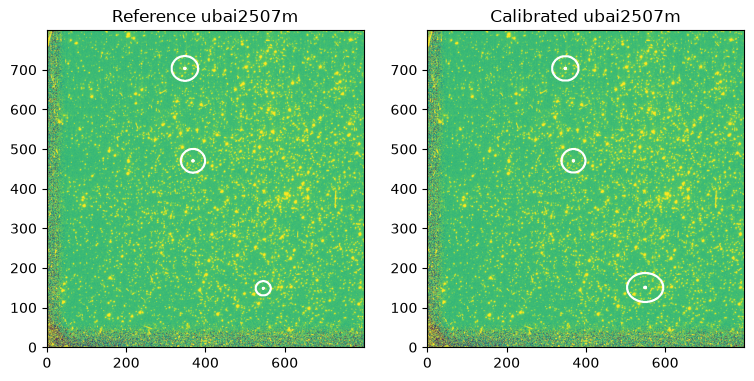

In [21]:
#Compare fitted gausian of the astronomical sources between the science-ready data and calibrated data
plt.close('all')
fig, (ax,ax1) = plt.subplots(1,2,figsize=(9, 9))

ax.imshow(fluxsqrt, origin='lower')
ax1.imshow(fluxsqrtcal, origin='lower')


for list in aligngauss:
    xvalsal, yvalsal = np.indices(aligned.shape)
    
    fitted_gaussian = Functions.gauss_2d(
        (yvalsal, xvalsal),
        *list
    ).reshape(aligned.shape)

    ax.contour(xvalsal, yvalsal, fitted_gaussian, levels=5, colors='white', vmin=0, vmax=5)
    
for list in calibrgauss:   
    yvalscal, xvalscal = np.indices(Calflux.shape)
    
    fitted_gaussian2 = Functions.gauss_2d(
        (yvalscal, xvalscal),
        *list
    ).reshape(Calflux.shape)
    
    ax1.contour(xvalscal, yvalscal, fitted_gaussian2, levels=5, colors='white', vmin=0, vmax=5)
ax.set_title("Reference ubai2507m")
ax1.set_title("Calibrated ubai2507m")
plt.show()

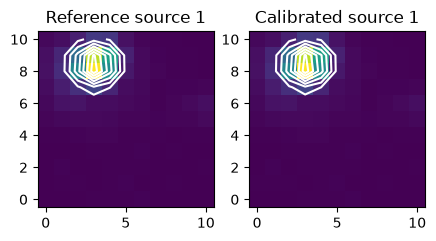

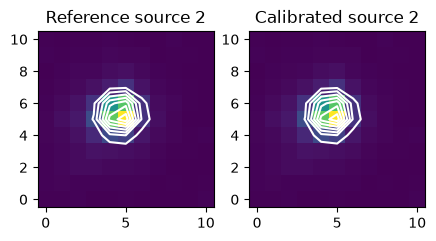

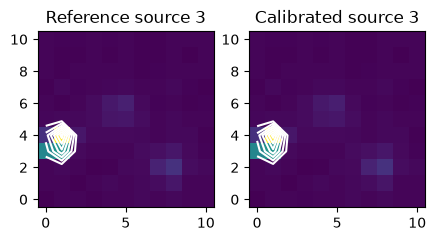

In [29]:
plt.close('all')
#crop the image to take a closer look at the astronomical source 2d gaussian fitting
for i, val in enumerate(test_coords):
    cutout = Functions.square_aperture(aligned, center=val, box_size=10)
    popt, pcov = Functions.fit_gauss_2d(cutout)

    cutout1 = Functions.square_aperture(Calflux, center=val, box_size=10)
    popt1, pcov1 = Functions.fit_gauss_2d(cutout1)
    
    fig, (ax,ax1) = plt.subplots(1,2,figsize=(5,5))
    ax.imshow(cutout, origin='lower')
    ax1.imshow(cutout1, origin='lower')
    
    yind, xind = np.indices(cutout.shape)
    fitted = Functions.gauss_2d([yind, xind], *popt).reshape(cutout.shape)
    yind1, xind1 = np.indices(cutout1.shape)
    fitted1 = Functions.gauss_2d([yind1, xind1], *popt1).reshape(cutout1.shape)

    ax.contour(xind, yind, fitted, levels=7, colors='white')
    ax1.contour(xind1, yind1, fitted1, levels=7, colors='white')

    ax.set_title(f"Reference source {i+1}")
    ax1.set_title(f"Calibrated source {i+1}")
    plt.show()
  